In [3]:
# En este proyecto se realizó un análisis completo de segmentación de clientes (clustering no supervisado) utilizando el conjunto de datos "Mall Customers", el cual contiene información básica de 200 clientes de un centro comercial.
# El dataset incluye las siguientes variables: identificador del cliente (CustomerID), género (Gender), edad (Age), ingreso anual en miles de dólares (Annual Income (k$)) y un puntaje de gasto (Spending Score, 1–100) que representa el comportamiento de compra del cliente.

#El trabajo abarcó desde el preprocesamiento de datos hasta la interpretación de perfiles de clientes para su uso en estrategias de marketing y e-commerce.
#Se realizó la limpieza y estandarización de los nombres de columnas, el tratamiento de variables categóricas mediante One-Hot Encoding (género) y la normalización de las variables numéricas para asegurar una correcta aplicación de los algoritmos de clustering.

#Se implementaron y compararon distintos métodos de clustering no supervisado: K-Means (base), K-Means++ (como versión mejorada en la inicialización de centroides), Clustering Jerárquico Aglomerativo (método Ward) y un enfoque Divisivo mediante Bisecting K-Means.
#La selección del número de clusters se realizó mediante el Método del Codo (SSE/Inercia) y se validó con métricas internas de calidad de clustering como Silhouette Score, Davies–Bouldin, Calinski–Harabasz.
#Se utilizaron visualizaciones 2D y 3D para analizar la separación de los grupos en el espacio de características.

#Finalmente, los clusters obtenidos (especialmente con K-Means++) fueron interpretados como perfiles de cliente en lenguaje sencillo, y se generaron datasets independientes por perfil junto con un resumen de estrategias de marketing y e-commerce, con el objetivo de traducir los resultados del análisis en acciones de negocio concretas.


In [56]:
# Importamos pandas para trabajar con tablas de datos
import pandas as pd

# Cargamos el archivo CSV con los datos de clientes
df = pd.read_csv("Mall_Customers.csv")

# Mostramos las primeras 5 filas para ver cómo se ven los datos
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [57]:
# Vemos cuántas filas (personas) y columnas (datos por persona) hay
df.shape

(200, 5)

In [6]:
# Vemos los nombres de las columnas (qué datos trae cada cliente)
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [7]:
# Vemos qué tipo de datos hay (números o texto) y si hay datos faltantes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [58]:
# Contamos cuántos datos faltan en cada columna
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [59]:
# Cambiamos los nombres de las columnas por nombres más fáciles de usar
df = df.rename(columns={
    "CustomerID": "id",
    "Gender": "gender",
    "Age": "age",
    "Annual Income (k$)": "annual_income",
    "Spending Score (1-100)": "spending_score"
})

# Verificamos que ya cambiaron los nombres
df.columns

Index(['id', 'gender', 'age', 'annual_income', 'spending_score'], dtype='object')

In [63]:
# Quitamos la columna id porque no aporta información al clustering
df_model = df.drop(columns=["id"])

df_model.head()

,gender,age,annual_income,spending_score
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [65]:
# Columnas numéricas
numeric_cols = ["age", "annual_income", "spending_score"]

# Columna categórica
categorical_cols = ["gender"]

In [67]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Normalizamos las columnas numéricas
df_model[numeric_cols] = scaler.fit_transform(df_model[numeric_cols])

df_model.head()

,gender,age,annual_income,spending_score
0,Male,0.019231,0.000000,0.387755
1,Male,0.057692,0.000000,0.816327
2,Female,0.038462,0.008197,0.051020
3,Female,0.096154,0.008197,0.775510
4,Female,0.250000,0.016393,0.397959


In [70]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Convertimos la columna gender
encoded_array = encoder.fit_transform(df_model[categorical_cols])

# Obtenemos los nombres de las nuevas columnas
encoded_cols = encoder.get_feature_names_out(categorical_cols)

# Creamos DataFrame con las columnas codificadas
df_encoded = pd.DataFrame(encoded_array, columns=encoded_cols)

# Alineamos índices
df_encoded.index = df_model.index

df_encoded.head()

,gender_Female,gender_Male
0,0.0,1.0
1,0.0,1.0
2,1.0,0.0
3,1.0,0.0
4,1.0,0.0


In [71]:
# Quitamos la columna categórica original
df_model_numeric = df_model.drop(columns=categorical_cols)

# Unimos datos numéricos normalizados + columnas codificadas
df_final = pd.concat([df_model_numeric, df_encoded], axis=1)

df_final.head()

,age,annual_income,spending_score,gender_Female,gender_Male
0,0.019231,0.000000,0.387755,0.0,1.0
1,0.057692,0.000000,0.816327,0.0,1.0
2,0.038462,0.008197,0.051020,1.0,0.0
3,0.096154,0.008197,0.775510,1.0,0.0
4,0.250000,0.016393,0.397959,1.0,0.0


In [15]:
df_final.describe()

,age,annual_income,spending_score,gender_Female,gender_Male
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.400962,0.373443,0.502041,0.560000,0.440000
std,0.268635,0.215285,0.263505,0.497633,0.497633
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.206731,0.217213,0.344388,0.000000,0.000000
50%,0.346154,0.381148,0.500000,1.000000,0.000000
75%,0.596154,0.516393,0.734694,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000


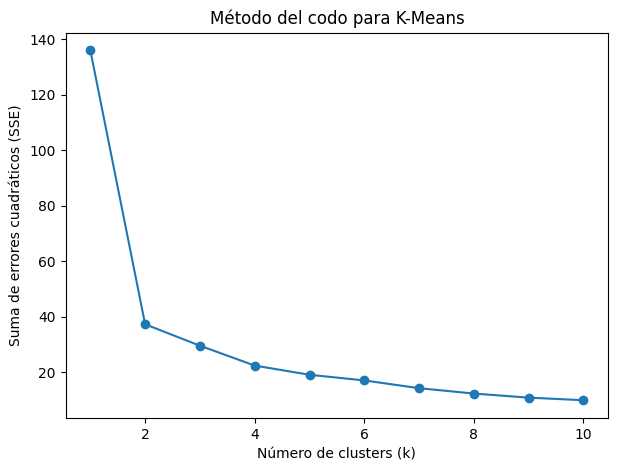

In [72]:
# Importamos el algoritmo KMeans para agrupar datos
from sklearn.cluster import KMeans

# Importamos matplotlib para hacer gráficas
import matplotlib.pyplot as plt

# Creamos una lista vacía para guardar el error de cada k (SSE)
sse = []

# Probamos diferentes números de clusters (de 2 a 10)
K = range(1, 11)

# Recorremos cada valor de k
for k in K:
    # Creamos el modelo KMeans con k clusters
    kmeans = KMeans(n_clusters=k, random_state=42,init="random")

    # Entrenamos el modelo con el dataset final
    kmeans.fit(df_final)

    # Guardamos el SSE (qué tan compactos están los clusters)
    sse.append(kmeans.inertia_)

# Hacemos la gráfica del método del codo
plt.figure(figsize=(7,5))
plt.plot(K, sse, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Suma de errores cuadráticos (SSE)")
plt.title("Método del codo para K-Means")
plt.show()

In [74]:
# Definimos el número de clusters que elegimos según el método del codo
k = 5

# Creamos el modelo KMeans con ese número de clusters
kmeans = KMeans(n_clusters=k, random_state=42,init="random")

# Entrenamos el modelo y obtenemos el cluster de cada persona
clusters_kmeans = kmeans.fit_predict(df_final)

# Copiamos el dataset original para no modificarlo
df_kmeans = df.copy()

# Agregamos la columna con el número de cluster asignado a cada persona
df_kmeans["cluster_kmeans"] = clusters_kmeans

# Mostramos las primeras filas para verificar
df_kmeans.head()

,id,gender,age,annual_income,spending_score,cluster_kmeans
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


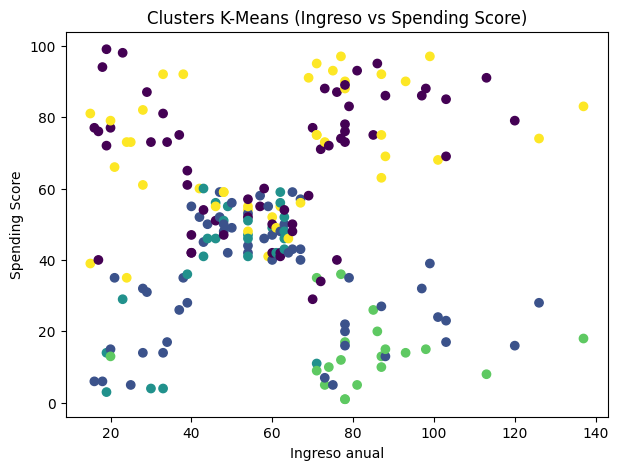

In [75]:
# Graficamos los clusters usando ingreso anual y nivel de gasto
plt.figure(figsize=(7,5))
plt.scatter(
    df_kmeans["annual_income"],
    df_kmeans["spending_score"],
    c=df_kmeans["cluster_kmeans"]
)

# Etiquetas de los ejes
plt.xlabel("Ingreso anual")
plt.ylabel("Spending Score")

# Título de la gráfica
plt.title("Clusters K-Means (Ingreso vs Spending Score)")

# Mostramos la gráfica
plt.show()

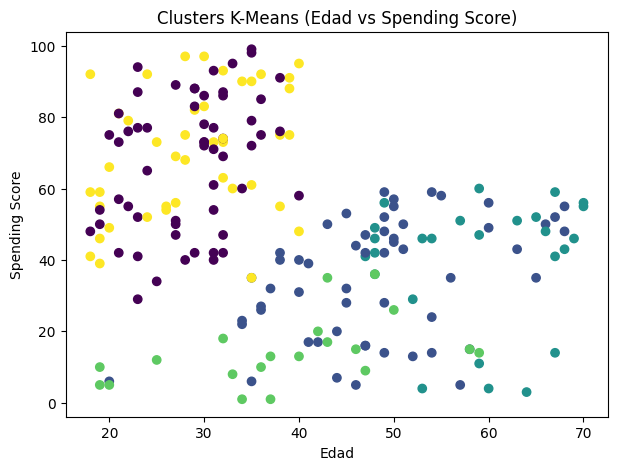

In [76]:
# Graficamos los clusters usando edad y nivel de gasto
plt.figure(figsize=(7,5))
plt.scatter(
    df_kmeans["age"],
    df_kmeans["spending_score"],
    c=df_kmeans["cluster_kmeans"]
)

# Etiquetas de los ejes
plt.xlabel("Edad")
plt.ylabel("Spending Score")

# Título de la gráfica
plt.title("Clusters K-Means (Edad vs Spending Score)")

# Mostramos la gráfica
plt.show()

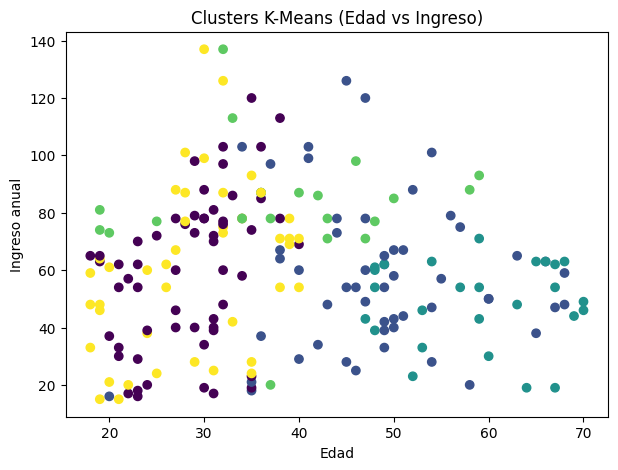

In [20]:
# Graficamos los clusters usando edad e ingreso anual
plt.figure(figsize=(7,5))
plt.scatter(
    df_kmeans["age"],
    df_kmeans["annual_income"],
    c=df_kmeans["cluster_kmeans"]
)

# Etiquetas de los ejes
plt.xlabel("Edad")
plt.ylabel("Ingreso anual")

# Título de la gráfica
plt.title("Clusters K-Means (Edad vs Ingreso)")
plt.show()

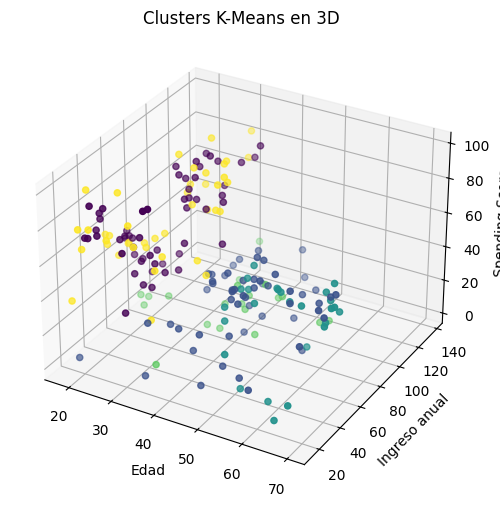

In [21]:
# Importamos Axes3D para poder hacer gráficas en 3D
from mpl_toolkits.mplot3d import Axes3D

# Creamos la figura 3D
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Graficamos los puntos en 3 dimensiones
ax.scatter(
    df_kmeans["age"],
    df_kmeans["annual_income"],
    df_kmeans["spending_score"],
    c=df_kmeans["cluster_kmeans"]
)

# Etiquetas de los ejes
ax.set_xlabel("Edad")
ax.set_ylabel("Ingreso anual")
ax.set_zlabel("Spending Score")

# Título de la gráfica
ax.set_title("Clusters K-Means en 3D")

# Mostramos la gráfica
plt.show()

In [22]:
# Importamos métricas para evaluar el clustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculamos el SSE (qué tan compactos están los clusters)
sse_kmeans = kmeans.inertia_

# Calculamos el índice de Silhouette (qué tan bien separados están los clusters)
silhouette_kmeans = silhouette_score(df_final, clusters_kmeans)

# Calculamos Davies-Bouldin (qué tan confundidos están los clusters)
db_kmeans = davies_bouldin_score(df_final, clusters_kmeans)

# Calculamos Calinski-Harabasz (qué tan bien definidos están los clusters)
ch_kmeans = calinski_harabasz_score(df_final, clusters_kmeans)

# Mostramos las métricas
sse_kmeans, silhouette_kmeans, db_kmeans, ch_kmeans

(19.08172248610557,
 np.float64(0.3706322619220125),
 np.float64(1.0184503187691676),
 np.float64(298.6045042982262))

In [77]:
# Calculamos el promedio de edad, ingreso y gasto por cluster
cluster_profile_kmeans = (
    df_kmeans
    .groupby("cluster_kmeans")[["age", "annual_income", "spending_score"]]
    .mean()
)

# Mostramos el perfil de cada grupo
cluster_profile_kmeans

,age,annual_income,spending_score
cluster_kmeans,,,
0,28.438596,59.666667,67.684211
1,48.109091,58.818182,34.781818
2,58.846154,48.692308,39.846154
3,38.400000,82.600000,14.150000
4,28.690476,60.904762,70.238095


In [78]:
# Creamos (o actualizamos) la tabla resumen de métricas
resultados = pd.DataFrame({
    "Algoritmo": ["KMeans"],
    "SSE": [sse_kmeans],
    "Silhouette": [silhouette_kmeans],
    "Davies-Bouldin": [db_kmeans],
    "Calinski-Harabasz": [ch_kmeans]
})

# Mostramos la tabla
resultados

,Algoritmo,SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,19.081722,0.370632,1.01845,298.604504


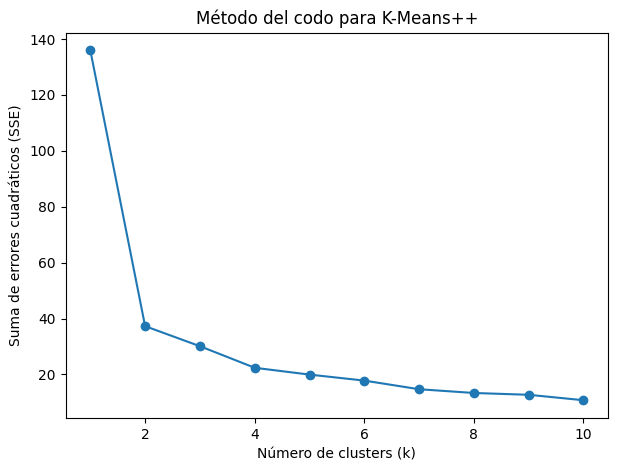

In [79]:
# Importamos KMeans para clustering
from sklearn.cluster import KMeans

# Importamos matplotlib para gráficas
import matplotlib.pyplot as plt

# Lista para guardar el SSE de cada valor de k
sse_kpp = []

# Probamos valores de k del 1 al 10
K = range(1, 11)

# Recorremos cada valor de k
for k in K:
    # Creamos KMeans con inicialización k-means++
    kmeans_pp = KMeans(n_clusters=k, init="k-means++", random_state=42)

    # Entrenamos el modelo
    kmeans_pp.fit(df_final)

    # Guardamos el SSE
    sse_kpp.append(kmeans_pp.inertia_)

# Graficamos el método del codo para K-Means++
plt.figure(figsize=(7,5))
plt.plot(K, sse_kpp, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Suma de errores cuadráticos (SSE)")
plt.title("Método del codo para K-Means++")
plt.show()

In [80]:
# Definimos el número de clusters
k = 5

# Creamos el modelo K-Means++ con k clusters
kmeans_pp = KMeans(n_clusters=k, init="k-means++", random_state=42)

# Entrenamos el modelo y obtenemos los clusters
clusters_kpp = kmeans_pp.fit_predict(df_final)

# Copiamos el dataset original
df_kmeans_pp = df.copy()

# Agregamos la columna con los clusters de K-Means++
df_kmeans_pp["cluster_kmeans_pp"] = clusters_kpp

# Mostramos las primeras filas
df_kmeans_pp.head()

,id,gender,age,annual_income,spending_score,cluster_kmeans_pp
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,1
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


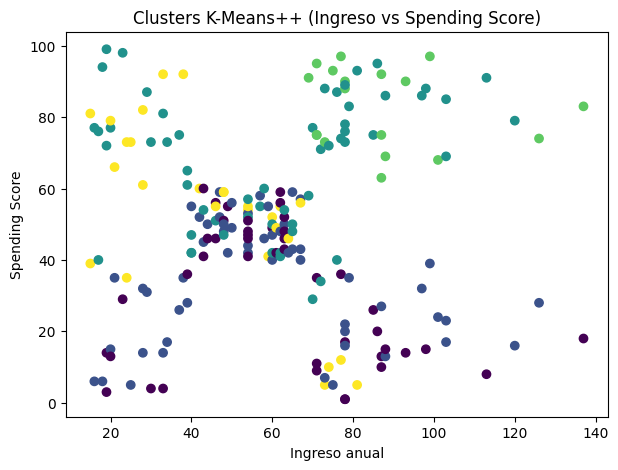

In [27]:
# Gráfica 2D usando ingreso anual y nivel de gasto
plt.figure(figsize=(7,5))
plt.scatter(
    df_kmeans_pp["annual_income"],
    df_kmeans_pp["spending_score"],
    c=df_kmeans_pp["cluster_kmeans_pp"]
)
plt.xlabel("Ingreso anual")
plt.ylabel("Spending Score")
plt.title("Clusters K-Means++ (Ingreso vs Spending Score)")
plt.show()

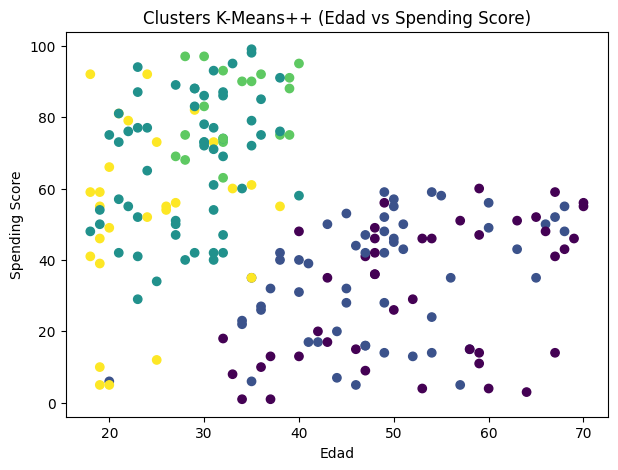

In [28]:
# Gráfica 2D usando edad y nivel de gasto
plt.figure(figsize=(7,5))
plt.scatter(
    df_kmeans_pp["age"],
    df_kmeans_pp["spending_score"],
    c=df_kmeans_pp["cluster_kmeans_pp"]
)
plt.xlabel("Edad")
plt.ylabel("Spending Score")
plt.title("Clusters K-Means++ (Edad vs Spending Score)")
plt.show()

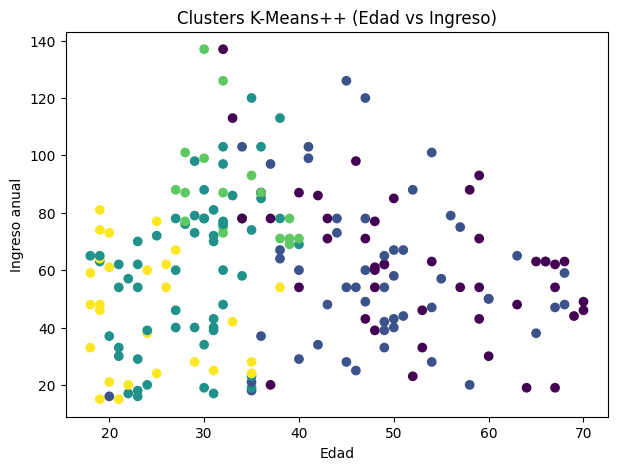

In [29]:
# Gráfica 2D usando edad e ingreso anual
plt.figure(figsize=(7,5))
plt.scatter(
    df_kmeans_pp["age"],
    df_kmeans_pp["annual_income"],
    c=df_kmeans_pp["cluster_kmeans_pp"]
)
plt.xlabel("Edad")
plt.ylabel("Ingreso anual")
plt.title("Clusters K-Means++ (Edad vs Ingreso)")
plt.show()

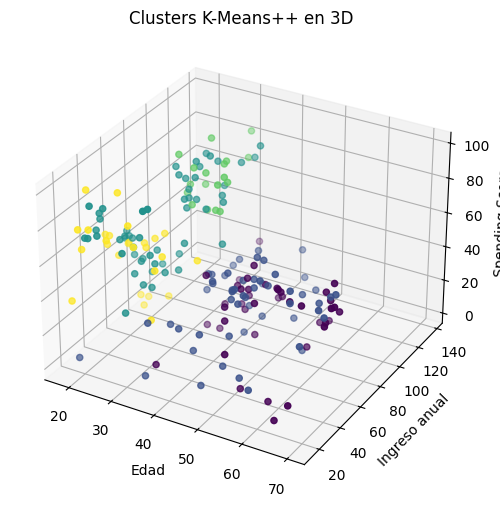

In [30]:
# Importamos herramientas para 3D
from mpl_toolkits.mplot3d import Axes3D

# Creamos figura 3D
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Graficamos los puntos en 3D
ax.scatter(
    df_kmeans_pp["age"],
    df_kmeans_pp["annual_income"],
    df_kmeans_pp["spending_score"],
    c=df_kmeans_pp["cluster_kmeans_pp"]
)

ax.set_xlabel("Edad")
ax.set_ylabel("Ingreso anual")
ax.set_zlabel("Spending Score")
ax.set_title("Clusters K-Means++ en 3D")
plt.show()

In [31]:
# Importamos métricas para evaluar clustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculamos SSE
sse_kpp_final = kmeans_pp.inertia_

# Calculamos Silhouette
silhouette_kpp = silhouette_score(df_final, clusters_kpp)

# Calculamos Davies-Bouldin
db_kpp = davies_bouldin_score(df_final, clusters_kpp)

# Calculamos Calinski-Harabasz
ch_kpp = calinski_harabasz_score(df_final, clusters_kpp)

# Mostramos las métricas
sse_kpp_final, silhouette_kpp, db_kpp, ch_kpp

(19.95224656212859,
 np.float64(0.3575309947302041),
 np.float64(1.0648873549085651),
 np.float64(283.44929568725235))

In [32]:
# Calculamos el perfil promedio de cada cluster
cluster_profile_kpp = (
    df_kmeans_pp
    .groupby("cluster_kmeans_pp")[["age", "annual_income", "spending_score"]]
    .mean()
)

cluster_profile_kpp

,age,annual_income,spending_score
cluster_kmeans_pp,,,
0,52.441860,62.023256,31.046512
1,48.109091,58.818182,34.781818
2,28.438596,59.666667,67.684211
3,33.277778,87.111111,82.666667
4,24.037037,45.962963,53.555556


In [33]:
# Agregamos los resultados de K-Means++ a la tabla comparativa
resultados = pd.concat([
    resultados,
    pd.DataFrame({
        "Algoritmo": ["KMeans++"],
        "SSE": [sse_kpp_final],
        "Silhouette": [silhouette_kpp],
        "Davies-Bouldin": [db_kpp],
        "Calinski-Harabasz": [ch_kpp]
    })
], ignore_index=True)

resultados

,Algoritmo,SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,19.081722,0.370632,1.018450,298.604504
1,KMeans++,19.952247,0.357531,1.064887,283.449296


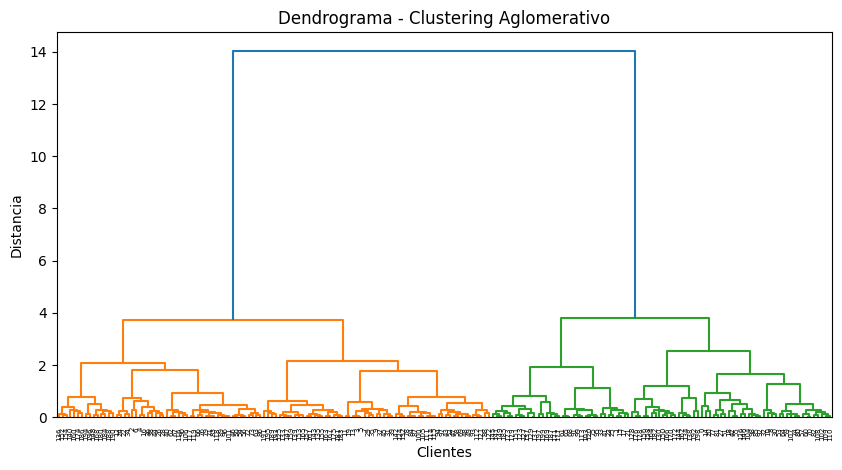

In [81]:
# Importamos funciones para hacer el dendrograma
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Creamos la matriz de enlaces usando el método ward (bueno para datos numéricos)
linked = linkage(df_final, method="ward")

# Hacemos el dendrograma
plt.figure(figsize=(10,5))
dendrogram(linked)
plt.title("Dendrograma - Clustering Aglomerativo")
plt.xlabel("Clientes")
plt.ylabel("Distancia")
plt.show()

In [82]:
# Importamos el modelo de clustering aglomerativo
from sklearn.cluster import AgglomerativeClustering

# Definimos el número de clusters según el dendrograma
k = 5
# Creamos el modelo aglomerativo
agglo = AgglomerativeClustering(n_clusters=k, linkage="ward")

# Entrenamos el modelo y obtenemos los clusters
clusters_agglo = agglo.fit_predict(df_final)

# Copiamos el dataset original
df_agglo = df.copy()

# Agregamos la columna de cluster
df_agglo["cluster_agglo"] = clusters_agglo

df_agglo.head()

,id,gender,age,annual_income,spending_score,cluster_agglo
0,1,Male,19,15,39,3
1,2,Male,21,15,81,2
2,3,Female,20,16,6,1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,1


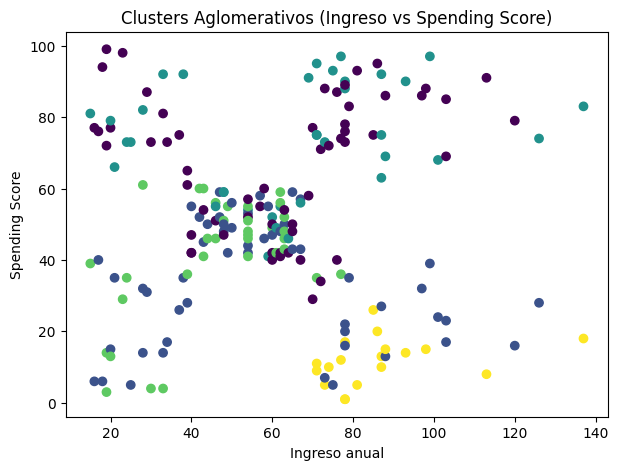

In [36]:
# Gráfica 2D: Ingreso vs Spending Score
plt.figure(figsize=(7,5))
plt.scatter(
    df_agglo["annual_income"],
    df_agglo["spending_score"],
    c=df_agglo["cluster_agglo"]
)
plt.xlabel("Ingreso anual")
plt.ylabel("Spending Score")
plt.title("Clusters Aglomerativos (Ingreso vs Spending Score)")
plt.show()

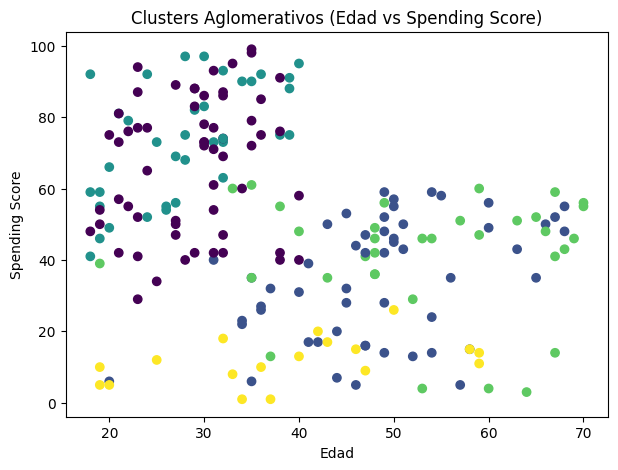

In [37]:
# Gráfica 2D: Edad vs Spending Score
plt.figure(figsize=(7,5))
plt.scatter(
    df_agglo["age"],
    df_agglo["spending_score"],
    c=df_agglo["cluster_agglo"]
)
plt.xlabel("Edad")
plt.ylabel("Spending Score")
plt.title("Clusters Aglomerativos (Edad vs Spending Score)")
plt.show()

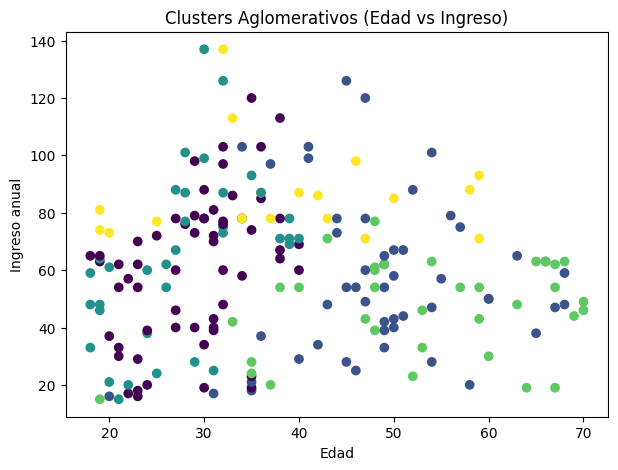

In [38]:
# Gráfica 2D: Edad vs Ingreso
plt.figure(figsize=(7,5))
plt.scatter(
    df_agglo["age"],
    df_agglo["annual_income"],
    c=df_agglo["cluster_agglo"]
)
plt.xlabel("Edad")
plt.ylabel("Ingreso anual")
plt.title("Clusters Aglomerativos (Edad vs Ingreso)")
plt.show()

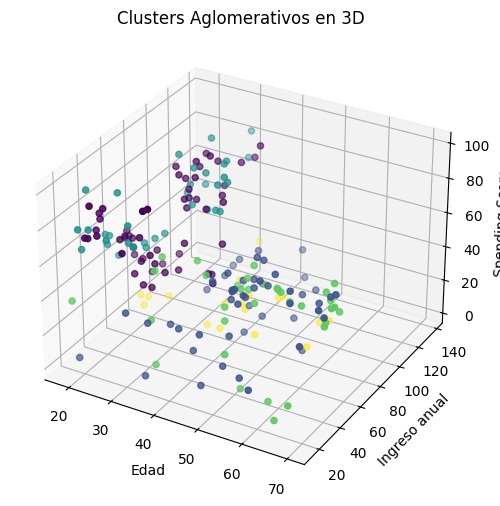

In [39]:
# Importamos herramientas para 3D
from mpl_toolkits.mplot3d import Axes3D

# Creamos figura 3D
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

# Graficamos los puntos en 3D
ax.scatter(
    df_agglo["age"],
    df_agglo["annual_income"],
    df_agglo["spending_score"],
    c=df_agglo["cluster_agglo"]
)

ax.set_xlabel("Edad")
ax.set_ylabel("Ingreso anual")
ax.set_zlabel("Spending Score")
ax.set_title("Clusters Aglomerativos en 3D")
plt.show()

In [40]:
# Importamos métricas de evaluación
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculamos Silhouette
silhouette_agglo = silhouette_score(df_final, clusters_agglo)

# Calculamos Davies-Bouldin
db_agglo = davies_bouldin_score(df_final, clusters_agglo)

# Calculamos Calinski-Harabasz
ch_agglo = calinski_harabasz_score(df_final, clusters_agglo)

silhouette_agglo, db_agglo, ch_agglo

(np.float64(0.35032447507156306),
 np.float64(1.0941951795238567),
 np.float64(284.11469477458803))

In [41]:
# Perfil promedio por cluster
cluster_profile_agglo = (
    df_agglo
    .groupby("cluster_agglo")[["age", "annual_income", "spending_score"]]
    .mean()
)

cluster_profile_agglo

,age,annual_income,spending_score
cluster_agglo,,,
0,28.915254,60.593220,66.779661
1,48.320755,57.754717,34.547170
2,27.916667,65.027778,73.666667
3,52.911765,46.470588,41.382353
4,38.833333,86.388889,11.666667


In [42]:
# Agregamos resultados del método aglomerativo a la tabla comparativa
resultados = pd.concat([
    resultados,
    pd.DataFrame({
        "Algoritmo": ["Aglomerativo"],
        "SSE": [None],  # No aplica para aglomerativo
        "Silhouette": [silhouette_agglo],
        "Davies-Bouldin": [db_agglo],
        "Calinski-Harabasz": [ch_agglo]
    })
], ignore_index=True)

resultados

/tmp/ipython-input-359/852926684.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  resultados = pd.concat([


,Algoritmo,SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,19.081722,0.370632,1.018450,298.604504
1,KMeans++,19.952247,0.357531,1.064887,283.449296
2,Aglomerativo,NaN,0.350324,1.094195,284.114695


In [43]:
# Definimos el número de clusters (usa el mismo k que en los otros modelos)
k = 5

# CORRECCIÓN 1: Importar la clase correcta
from sklearn.cluster import BisectingKMeans

# CORRECCIÓN 2: Instanciar el modelo correctamente
clusters_div = BisectingKMeans(n_clusters=k, init="random", random_state=42)

# CORRECCIÓN 3: Entrenar y predecir con el nombre correcto de la variable
clusters_div_clus = clusters_div.fit_predict(df_final)  # Cambié cluster_div por clusters_div

# Copiamos el dataset original
df_div = df.copy()

# CORRECCIÓN 4: Usar las predicciones guardadas en clusters_div_clus
df_div["cluster_divisivo"] = clusters_div_clus  # Cambié clusters_div por clusters_div_clus

# Verificamos las primeras filas
df_div.head()

,id,gender,age,annual_income,spending_score,cluster_divisivo
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,3


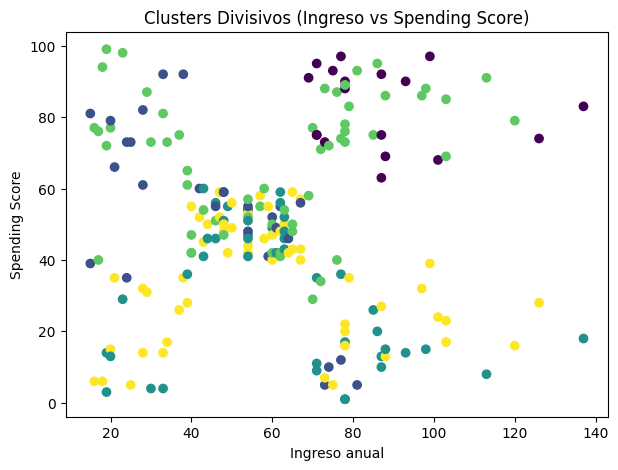

In [44]:
# Gráfica 2D: Ingreso vs Spending Score
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.scatter(
    df_div["annual_income"],
    df_div["spending_score"],
    c=df_div["cluster_divisivo"]
)
plt.xlabel("Ingreso anual")
plt.ylabel("Spending Score")
plt.title("Clusters Divisivos (Ingreso vs Spending Score)")
plt.show()

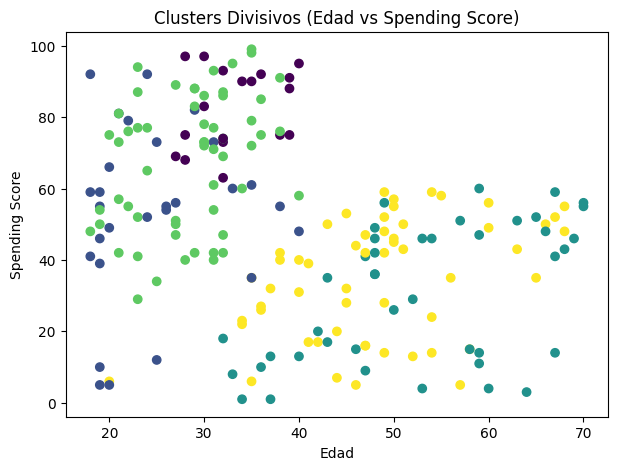

In [45]:
# Gráfica 2D: Edad vs Spending Score
plt.figure(figsize=(7,5))
plt.scatter(
    df_div["age"],
    df_div["spending_score"],
    c=df_div["cluster_divisivo"]
)
plt.xlabel("Edad")
plt.ylabel("Spending Score")
plt.title("Clusters Divisivos (Edad vs Spending Score)")
plt.show()

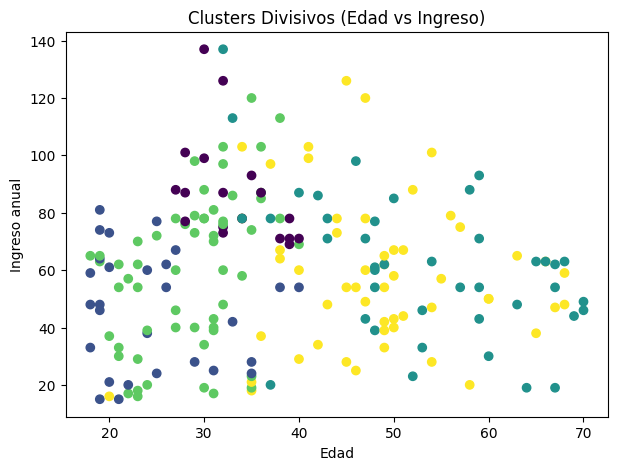

In [46]:
# Gráfica 2D: Edad vs Ingreso
plt.figure(figsize=(7,5))
plt.scatter(
    df_div["age"],
    df_div["annual_income"],
    c=df_div["cluster_divisivo"]
)
plt.xlabel("Edad")
plt.ylabel("Ingreso anual")
plt.title("Clusters Divisivos (Edad vs Ingreso)")
plt.show()

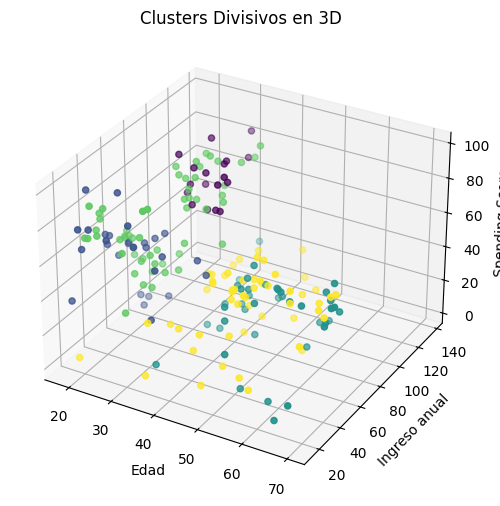

In [47]:
# Importamos herramientas para 3D
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    df_div["age"],
    df_div["annual_income"],
    df_div["spending_score"],
    c=df_div["cluster_divisivo"]
)

ax.set_xlabel("Edad")
ax.set_ylabel("Ingreso anual")
ax.set_zlabel("Spending Score")
ax.set_title("Clusters Divisivos en 3D")
plt.show()

In [48]:

# Importamos métricas de evaluación
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculamos métricas para el método divisivo
silhouette_div = silhouette_score(df_final, clusters_div_clus)
db_div = davies_bouldin_score(df_final, clusters_div_clus)
ch_div = calinski_harabasz_score(df_final, clusters_div_clus)

silhouette_div, db_div, ch_div

(np.float64(0.3563089889280583),
 np.float64(1.071600866966608),
 np.float64(283.37479358629236))

In [49]:
# Perfil promedio por cluster
cluster_profile_div = (
    df_div
    .groupby("cluster_divisivo")[["age", "annual_income", "spending_score"]]
    .mean()
)

cluster_profile_div

,age,annual_income,spending_score
cluster_divisivo,,,
0,33.277778,87.111111,82.666667
1,24.607143,46.250000,53.357143
2,52.738095,62.214286,30.642857
3,28.438596,59.666667,67.684211
4,48.109091,58.818182,34.781818


In [50]:
# Agregamos resultados del método divisivo a la tabla comparativa
resultados = pd.concat([
    resultados,
    pd.DataFrame({
        "Algoritmo": ["Divisivo (Bisecting K-Means)"],
        "SSE": [None],
        "Silhouette": [silhouette_div],
        "Davies-Bouldin": [db_div],
        "Calinski-Harabasz": [ch_div]
    })
], ignore_index=True)

resultados

/tmp/ipython-input-359/3901166297.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  resultados = pd.concat([


,Algoritmo,SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,19.081722,0.370632,1.018450,298.604504
1,KMeans++,19.952247,0.357531,1.064887,283.449296
2,Aglomerativo,NaN,0.350324,1.094195,284.114695
3,Divisivo (Bisecting K-Means),NaN,0.356309,1.071601,283.374794


In [51]:
perfiles_kpp = (
    df_kmeans_pp
    .groupby("cluster_kmeans_pp")[["age", "annual_income", "spending_score"]]
    .mean()
    .reset_index()
)

perfiles_kpp

,cluster_kmeans_pp,age,annual_income,spending_score
0,0,52.441860,62.023256,31.046512
1,1,48.109091,58.818182,34.781818
2,2,28.438596,59.666667,67.684211
3,3,33.277778,87.111111,82.666667
4,4,24.037037,45.962963,53.555556


In [83]:
# Obtenemos la lista de clusters únicos del modelo K-Means++
clusters = sorted(df_kmeans_pp["cluster_kmeans_pp"].unique())

# Recorremos cada cluster para crear un archivo CSV con sus clientes
for cid in clusters:
    # Filtramos solo los clientes que pertenecen a ese cluster
    df_cluster = df_kmeans_pp[df_kmeans_pp["cluster_kmeans_pp"] == cid]

    # Guardamos ese grupo en un archivo CSV independiente
    df_cluster.to_csv(f"clientes_perfil_{cid}.csv", index=False)

# Mostramos qué clusters se generaron
clusters

[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]

In [53]:
# Tabla de perfiles corregida según los promedios reales de K-Means++
perfiles = pd.DataFrame({
    "cluster": [0, 1, 2, 3, 4],
    "nombre_perfil": [
        "Adultos austeros con ingreso medio",
        "Adultos prudentes de consumo moderado",
        "Jóvenes entusiastas del consumo",
        "Compradores premium de alto valor",
        "Jóvenes de presupuesto limitado pero activos"
    ],
    "descripcion": [
        "Personas de mayor edad, con ingresos promedio y bajo nivel de gasto. Prefieren compras necesarias y evitan gastos impulsivos.",
        "Adultos de edad media, con ingresos medios y gasto bajo-moderado. Compran de forma cuidadosa y planeada.",
        "Clientes jóvenes con ingresos medios que presentan alto nivel de gasto. Son más impulsivos y sensibles a tendencias.",
        "Adultos jóvenes con los ingresos más altos y el mayor nivel de gasto. Representan el segmento más rentable.",
        "Clientes jóvenes con ingresos más bajos pero con gasto moderado. Buscan buen precio y promociones."
    ],
    "estrategia_marketing": [
        "Ofertas de productos básicos, paquetes de ahorro y descuentos por volumen.",
        "Promociones racionales, comparativas de valor y programas de lealtad.",
        "Lanzamientos, descuentos temporales, promociones en redes sociales.",
        "Experiencias premium, preventas exclusivas, productos de alta gama.",
        "Cupones, descuentos por tiempo limitado y promociones accesibles."
    ]
})

perfiles

,cluster,nombre_perfil,descripcion,estrategia_marketing
0,0,Adultos austeros con ingreso medio,"Personas de mayor edad, con ingresos promedio ...","Ofertas de productos básicos, paquetes de ahor..."
1,1,Adultos prudentes de consumo moderado,"Adultos de edad media, con ingresos medios y g...","Promociones racionales, comparativas de valor ..."
2,2,Jóvenes entusiastas del consumo,Clientes jóvenes con ingresos medios que prese...,"Lanzamientos, descuentos temporales, promocion..."
3,3,Compradores premium de alto valor,Adultos jóvenes con los ingresos más altos y e...,"Experiencias premium, preventas exclusivas, pr..."
4,4,Jóvenes de presupuesto limitado pero activos,Clientes jóvenes con ingresos más bajos pero c...,"Cupones, descuentos por tiempo limitado y prom..."


In [54]:
# Unimos la información de perfiles al dataset completo de K-Means++
df_kmeans_pp_perfil = df_kmeans_pp.merge(
    perfiles,
    left_on="cluster_kmeans_pp",
    right_on="cluster",
    how="left"
)

# Mostramos algunas filas
df_kmeans_pp_perfil.head()

,id,gender,age,annual_income,spending_score,cluster_kmeans_pp,cluster,nombre_perfil,descripcion,estrategia_marketing
0,1,Male,19,15,39,4,4,Jóvenes de presupuesto limitado pero activos,Clientes jóvenes con ingresos más bajos pero c...,"Cupones, descuentos por tiempo limitado y prom..."
1,2,Male,21,15,81,4,4,Jóvenes de presupuesto limitado pero activos,Clientes jóvenes con ingresos más bajos pero c...,"Cupones, descuentos por tiempo limitado y prom..."
2,3,Female,20,16,6,1,1,Adultos prudentes de consumo moderado,"Adultos de edad media, con ingresos medios y g...","Promociones racionales, comparativas de valor ..."
3,4,Female,23,16,77,2,2,Jóvenes entusiastas del consumo,Clientes jóvenes con ingresos medios que prese...,"Lanzamientos, descuentos temporales, promocion..."
4,5,Female,31,17,40,2,2,Jóvenes entusiastas del consumo,Clientes jóvenes con ingresos medios que prese...,"Lanzamientos, descuentos temporales, promocion..."


In [84]:
# Guardamos el dataset completo con perfiles para uso externo
df_kmeans_pp_perfil.to_csv("clientes_segmentados_con_perfiles.csv", index=False)